In [3]:
!pip install mne

   ---------------------------------------- 0.0/7.4 MB ? eta -:--:--
   ---------------------------------------- 7.4/7.4 MB 38.1 MB/s eta 0:00:00


In [5]:
import os
import mne
import numpy as np
import pandas as pd
from tqdm import tqdm

In [ ]:
#We create a helper function to read and filter each EEG recording.
#Returns EEG data as NumPy arrays for modeling.

In [9]:
# Base directory where the dataset is extracted
base_path = "C:/Users/User/Desktop/NeuroScience_Practice/eeg_data/files" 

# Function to load data from a single EDF file
def load_eeg_file(file_path):
    raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)
    raw.filter(1., 40.)  # bandpass filter 1–40 Hz
    data = raw.get_data()
    sfreq = raw.info['sfreq']
    return data, sfreq, raw

In [ ]:
#Parse Multiple Files Automatically
#Iterates through each participant and selected runs.
#Reads EEG signals and associated event markers.
#Creates label arrays for classification (0 = left, 1 = right).

In [13]:
all_data = []
all_labels = []

subjects = ["S001"]  # You can add more later

for subj in subjects:
    subj_path = os.path.join(base_path, subj)
    
    for run in range(4, 8):  # Runs 4–7 = motor imagery (left/right hand)
        edf_file = os.path.join(subj_path, f"{subj}R{run:02}.edf")
        
        if not os.path.exists(edf_file):
            print(f"File not found: {edf_file}")
            continue
        
        data, sfreq, raw = load_eeg_file(edf_file)

        # Extract event markers directly from annotations in the EDF
        events, event_dict = mne.events_from_annotations(raw)
        print(f"\n{edf_file} -> Found {len(events)} events.")
        print("Event mapping:", event_dict)

        # Map event IDs (adjust depending on what you see printed)
        for event in events:
            label_id = event[2]  # The numeric event code
            all_data.append(data)
            all_labels.append(label_id)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 529 samples (3.306 s)

Used Annotations descriptions: ['T0', 'T1', 'T2']

C:/Users/User/Desktop/NeuroScience_Practice/eeg_data/files\S001\S001R04.edf -> Found 30 events.
Event mapping: {'T0': 1, 'T1': 2, 'T2': 3}
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming 

In [17]:
import numpy as np
from scipy.signal import welch

# Convert lists to arrays
X = np.array(all_data)
y = np.array(all_labels)

print("Data shape:", X.shape)  # Expect (samples, channels, timepoints)
print("Labels shape:", y.shape)

def extract_features_multichannel(eeg_signal, sfreq):
    """Extract statistical + frequency features across all EEG channels."""
    features = []

    # 1️⃣ Statistical features per channel (mean, std, etc.)
    features.append(np.mean(eeg_signal, axis=1).mean())  # mean across all channels
    features.append(np.std(eeg_signal, axis=1).mean())
    features.append(np.var(eeg_signal, axis=1).mean())
    features.append(np.median(eeg_signal, axis=1).mean())
    features.append(np.ptp(eeg_signal, axis=1).mean())  # peak-to-peak (range)

    # 2️⃣ Frequency features using Welch per channel
    freqs, psd = welch(eeg_signal, sfreq, nperseg=sfreq*2, axis=1)
    psd_mean = np.mean(psd, axis=0)  # average PSD across channels

    def bandpower(fmin, fmax):
        idx_band = np.logical_and(freqs >= fmin, freqs <= fmax)
        return np.trapz(psd_mean[idx_band], freqs[idx_band])

    # Compute power in common EEG bands
    features.append(bandpower(1, 4))    # Delta
    features.append(bandpower(4, 8))    # Theta
    features.append(bandpower(8, 13))   # Alpha
    features.append(bandpower(13, 30))  # Beta
    features.append(bandpower(30, 40))  # Gamma

    return np.array(features)

# Apply feature extraction to each sample
feature_list = []
for i, eeg_signal in enumerate(X):
    feat = extract_features_multichannel(eeg_signal, sfreq)
    feature_list.append(feat)

X_features = np.array(feature_list)
print("✅ Feature matrix shape:", X_features.shape)


Data shape: (120, 64, 20000)
Labels shape: (120,)
✅ Feature matrix shape: (120, 10)


✅ Model Accuracy: 50.00%

Classification Report:
              precision    recall  f1-score   support

           1       0.50      1.00      0.67        12
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00         6

    accuracy                           0.50        24
   macro avg       0.17      0.33      0.22        24
weighted avg       0.25      0.50      0.33        24



C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


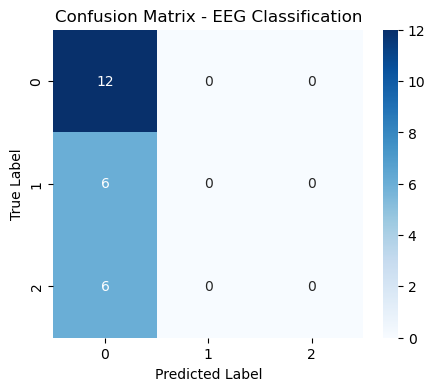

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1️⃣ Split data into train & test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y, test_size=0.2, random_state=42, stratify=y
)

# 2️⃣ Normalize features (important for SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3️⃣ Initialize and train SVM model
svm_model = SVC(kernel='rbf', C=1, gamma='scale', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# 4️⃣ Make predictions
y_pred = svm_model.predict(X_test_scaled)

# 5️⃣ Evaluate performance
acc = accuracy_score(y_test, y_pred)
print(f"✅ Model Accuracy: {acc*100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# 6️⃣ Confusion Matrix Visualization
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - EEG Classification")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


In [21]:
import numpy as np
unique, counts = np.unique(y, return_counts=True)
print(dict(zip(unique, counts)))


{1: 60, 2: 31, 3: 29}


Class distribution after oversampling:
{1: 60, 2: 60, 3: 60}
✅ Model Accuracy (after balancing): 30.56%

              precision    recall  f1-score   support

           1       0.31      0.33      0.32        12
           2       0.33      0.50      0.40        12
           3       0.20      0.08      0.12        12

    accuracy                           0.31        36
   macro avg       0.28      0.31      0.28        36
weighted avg       0.28      0.31      0.28        36



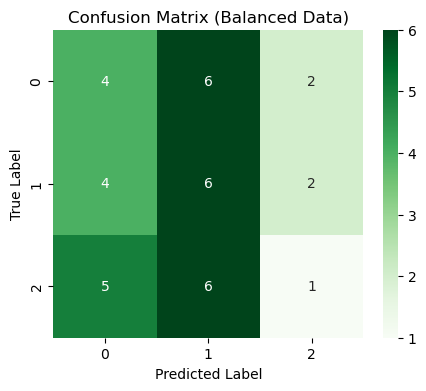

In [23]:
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# 1️⃣ Balance the dataset
ros = RandomOverSampler(random_state=42)
X_balanced, y_balanced = ros.fit_resample(X_features, y)

print("Class distribution after oversampling:")
unique, counts = np.unique(y_balanced, return_counts=True)
print(dict(zip(unique, counts)))

# 2️⃣ Split and scale again
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced, y_balanced, test_size=0.2, random_state=42, stratify=y_balanced
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3️⃣ Train SVM
svm_model = SVC(kernel='rbf', C=1, gamma='scale', random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred = svm_model.predict(X_test_scaled)

# 4️⃣ Evaluate again
acc = accuracy_score(y_test, y_pred)
print(f"✅ Model Accuracy (after balancing): {acc*100:.2f}%\n")
print(classification_report(y_test, y_pred, zero_division=0))

plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix (Balanced Data)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


✅ Random Forest Accuracy: 25.00%

Classification Report:
              precision    recall  f1-score   support

           1       0.32      0.58      0.41        12
           2       0.11      0.08      0.10        12
           3       0.20      0.08      0.12        12

    accuracy                           0.25        36
   macro avg       0.21      0.25      0.21        36
weighted avg       0.21      0.25      0.21        36



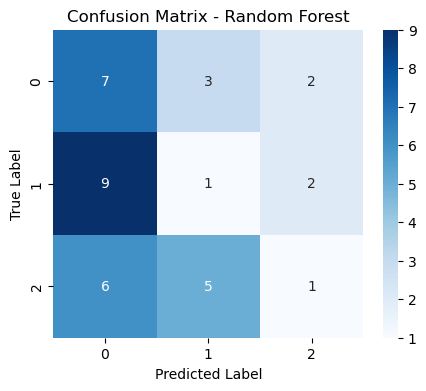

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Use the balanced dataset from before
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced, y_balanced, test_size=0.2, random_state=42, stratify=y_balanced
)

# No need to scale features for Random Forest

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,       # number of trees
    max_depth=None,         # grow until leaves are pure
    random_state=42,
    class_weight='balanced' # automatically handle class imbalance
)

# Train
rf_model.fit(X_train, y_train)

# Predict
y_pred = rf_model.predict(X_test)

# Evaluate
acc = accuracy_score(y_test, y_pred)
print(f"✅ Random Forest Accuracy: {acc*100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()
